<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/08_pytorch_paper_replicating_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08. PyTorch Paper Replicating Exercises

Welcome to the 08. PyTorch Paper Replicating exercises.

Your objective is to write code to satisify each of the exercises below.

Some starter code has been provided to make sure you have all the resources you need.

> **Note:** There may be more than one solution to each of the exercises.

## Resources

1. These exercises/solutions are based on [section 08. PyTorch Paper Replicating](https://www.learnpytorch.io/08_pytorch_paper_replicating/) of the Learn PyTorch for Deep Learning course by Zero to Mastery.
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/tjpW_BY8y3g) (but try the exercises yourself first!).
3. See [all solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

> **Note:** The first section of this notebook is dedicated to getting various helper functions and datasets used for the exercises. The exercises start at the heading "Exercise 1: ...".

### Get various imports and helper functions

The code in the following cells prepares imports and data for the exercises below. They are taken from [08. PyTorch Paper Replicating](https://www.learnpytorch.io/08_pytorch_paper_replicating/). 

In [2]:
import torch
import torchvision

In [3]:
# Continue with regular imports
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
import torchvision.transforms.v2 as T

from torchinfo import summary

from going_modular import data_setup, engine
from helper_functions import download_data, set_seeds, plot_loss_curves

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

### Get data

Want to download the data we've been using in PyTorch Paper Replicating: https://www.learnpytorch.io/08_pytorch_paper_replicating/#1-get-data

In [5]:
# Download pizza, steak, sushi images from GitHub
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data\pizza_steak_sushi directory exists, skipping download.


WindowsPath('data/pizza_steak_sushi')

In [6]:
# Setup directory paths to train and test images
train_dir = image_path / "train"
test_dir = image_path / "test"

### Preprocess data

Turn images into tensors using same code as PyTorch Paper Replicating section 2.1 and 2.2: https://www.learnpytorch.io/08_pytorch_paper_replicating/#21-prepare-transforms-for-images

In [7]:
# Create image size (from Table 3 in the ViT paper) 
IMG_SIZE = 224

# Create transform pipeline manually
manual_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToImage(),
    T.ToDtype(torch.float32, True)
])           
print(f"Manually created transforms: {manual_transforms}")

Manually created transforms: Compose(
      Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
      ToImage()
      ToDtype(scale=True)
)


In [8]:
# Set the batch size
BATCH_SIZE = 32 # this is lower than the ViT paper but it's because we're starting small

# Create data loaders
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    train_transform=manual_transforms, # use manually created transforms
    test_transform=manual_transforms,
    batch_size=BATCH_SIZE
)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x1d7272bd100>,
 ['pizza', 'steak', 'sushi'])

In [8]:
# Get a batch of images
image_batch, label_batch = next(iter(train_dataloader))

# Get a single image from the batch
image, label = image_batch[0], label_batch[0]

# View the batch shapes
image.shape, label

(torch.Size([3, 224, 224]), tensor(1))

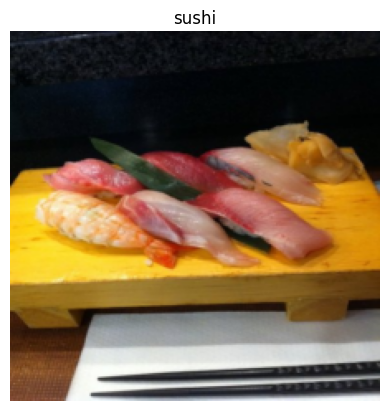

In [12]:
# Plot image with matplotlib
plt.imshow(image.permute(1, 2, 0)) # rearrange image dimensions to suit matplotlib [color_channels, height, width] -> [height, width, color_channels]
plt.title(class_names[label])
plt.axis(False);

## 1. Replicate the ViT architecture we created with in-built [PyTorch transformer layers](https://pytorch.org/docs/stable/nn.html#transformer-layers).

* You'll want to look into replacing our `TransformerEncoderBlock()` class with [`torch.nn.TransformerEncoderLayer()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html#torch.nn.TransformerEncoderLayer) (these contain the same layers as our custom blocks). 
* You can stack `torch.nn.TransformerEncoderLayer()`'s on top of each other with [`torch.nn.TransformerEncoder()`](https://pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html#torch.nn.TransformerEncoder).

In [9]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size:int=224, patch_size: int=16, in_channels=3):
        super().__init__()
        self.conv2d = nn.Conv2d(in_channels=in_channels, out_channels=patch_size**2 * in_channels, kernel_size=patch_size, stride=patch_size, padding=0)
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.flatten(self.conv2d(x)).permute(0, 2, 1)

In [20]:
from torchinfo import summary
from typing import List, Tuple
from torchinfo import ModelStatistics

def show_model_summary(model: nn.Module,
                       input_size: Tuple[int, ...] | None,
                       col_names: List[str] | None=["input_size", "output_size", "num_params", "trainable"],
                       col_width: int=20,
                       row_settings: List[str]=["var_names"]) -> ModelStatistics:
    return summary(model= model,
            input_size=input_size,
            col_names=col_names,
            col_width=col_width,
            row_settings=row_settings)

In [11]:
patchify = PatchEmbedding()
show_model_summary(patchify, input_size=(1, 3, 224, 224))

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (conv2d)                        [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

In [12]:
class ViT(nn.Module):
    def __init__(self,
                 img_size: int=224,
                 patch_size: int=16,
                 in_channels=3,
                 embedding_dim: int=768,
                 num_heads:int =12,
                 mlp_size: int=3072,
                 num_transformers=12,
                 dropout=0.1,
                 num_classes: int=3,
                 device: str=device):
        super().__init__()
        self.num_patches = img_size**2 // patch_size**2
        assert(img_size**2 % patch_size**2 == 0)
        
        self.pathify = PatchEmbedding(img_size, patch_size, in_channels)
        
        self.class_token = nn.Parameter(torch.randn(size=(1, 1, embedding_dim)), requires_grad=True)
        self.position_embedding = nn.Parameter(torch.randn(1, self.num_patches+1, embedding_dim), requires_grad=True)
        self.embedding_dropout = nn.Dropout(p=dropout)
        
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer=nn.TransformerEncoderLayer(d_model=embedding_dim,
                                                                    nhead=num_heads,
                                                                    dim_feedforward=mlp_size,
                                                                    dropout=dropout,
                                                                    activation="gelu",
                                                                    batch_first=True,
                                                                    norm_first=True),
                                                         num_layers=num_transformers
                                                         )
        self.classifier = nn.Sequential(
            nn.LayerNorm(normalized_shape=embedding_dim),
            nn.Linear(in_features=embedding_dim,
                    out_features=num_classes)
        )
    
    def forward(self, x:torch.Tensor) -> torch.Tensor:
        batch_size = x.shape[0]
        # Equation 1
        x = self.pathify(x)
        
        # expand class token's batch_size
        class_token = self.class_token.expand(size=(batch_size, -1, -1))
        # add class token embedding
        x = torch.cat((class_token, x), dim=1)
        # add position embedding
        x = x + self.position_embedding
        # embedding dropout
        x = self.embedding_dropout(x)
        # Equation 2-3
        x = self.transformer_encoder(x)
                
        # get class token logit and classify
        return self.classifier(x[:, 0, :])
        

In [13]:
demo_img = torch.randn(1, 3, 224, 224).to(device)
print(demo_img.shape) 

# Create ViT
vit = ViT(num_classes=len(class_names)).to(device)
vit(demo_img)

torch.Size([1, 3, 224, 224])


C:\Users\81456\AppData\Local\Temp\ipykernel_38856\2769476286.py:23: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(encoder_layer=nn.TransformerEncoderLayer(d_model=embedding_dim,


tensor([[-0.6544,  0.4879,  0.5358]], device='cuda:0',
       grad_fn=<AddmmBackward0>)

## 2. Turn the custom ViT architecture we created into a Python script, for example, `vit.py`.

* You should be able to import an entire ViT model using something like`from vit import ViT`.
* We covered the art of turning code cells into Python scrips in [05. PyTorch Going Modular](https://www.learnpytorch.io/05_pytorch_going_modular/). 


In [42]:
%%writefile vit.py
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"

class PatchEmbedding(nn.Module):
    def __init__(self, img_size:int=224, patch_size: int=16, in_channels=3):
        super().__init__()
        self.conv2d = nn.Conv2d(in_channels=in_channels, out_channels=patch_size**2 * in_channels, kernel_size=patch_size, stride=patch_size, padding=0)
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.flatten(self.conv2d(x)).permute(0, 2, 1)

class ViT(nn.Module):
    def __init__(self,
                 img_size: int=224,
                 patch_size: int=16,
                 in_channels=3,
                 embedding_dim: int=768,
                 num_heads:int =12,
                 mlp_size: int=3072,
                 num_transformers=12,
                 dropout=0.1,
                 num_classes: int=3,
                 device: str=device):
        super().__init__()
        self.num_patches = img_size**2 // patch_size**2
        assert(img_size**2 % patch_size**2 == 0)
        
        self.pathify = PatchEmbedding(img_size, patch_size, in_channels)
        
        self.class_token = nn.Parameter(torch.randn(size=(1, 1, embedding_dim)), requires_grad=True)
        self.position_embedding = nn.Parameter(torch.randn(1, self.num_patches+1, embedding_dim), requires_grad=True)
        self.embedding_dropout = nn.Dropout(p=dropout)
        
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer=nn.TransformerEncoderLayer(d_model=embedding_dim,
                                                                    nhead=num_heads,
                                                                    dim_feedforward=mlp_size,
                                                                    dropout=dropout,
                                                                    activation="gelu",
                                                                    batch_first=True,
                                                                    norm_first=True),
                                                         num_layers=num_transformers
                                                         )
        self.classifier = nn.Sequential(
            nn.LayerNorm(normalized_shape=embedding_dim),
            nn.Linear(in_features=embedding_dim,
                    out_features=num_classes)
        )
    
    def forward(self, x:torch.Tensor) -> torch.Tensor:
        batch_size = x.shape[0]
        # Equation 1
        x = self.pathify(x)
        
        # expand class token's batch_size
        class_token = self.class_token.expand(size=(batch_size, -1, -1))
        # add class token embedding
        x = torch.cat((class_token, x), dim=1)
        # add position embedding
        x = x + self.position_embedding
        # embedding dropout
        x = self.embedding_dropout(x)
        # Equation 2-3
        x = self.transformer_encoder(x)
                
        # get class token logit and classify
        return self.classifier(x[:, 0, :])
        

Overwriting vit.py


## 3. Train a pretrained ViT feature extractor model (like the one we made in [08. PyTorch Paper Replicating section 10](https://www.learnpytorch.io/08_pytorch_paper_replicating/#10-bring-in-pretrained-vit-from-torchvisionmodels-on-same-dataset)) on 20% of the pizza, steak and sushi data like the dataset we used in [07. PyTorch Experiment Tracking section 7.3](https://www.learnpytorch.io/07_pytorch_experiment_tracking/#73-download-different-datasets) 
* See how it performs compared to the EffNetB2 model we compared it to in [08. PyTorch Paper Replicating section 10.6](https://www.learnpytorch.io/08_pytorch_paper_replicating/#106-save-feature-extractor-vit-model-and-check-file-size).

In [9]:
vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT
vit = torchvision.models.vit_b_16(weights=vit_weights).to(device)
transforms = vit_weights.transforms()

In [10]:
for param in vit.parameters():
    param.requires_grad = False

In [14]:
from going_modular import data_setup
train_dir = "data/pizza_steak_sushi_20_percent/train"
test_dir = "data/pizza_steak_sushi_20_percent/test"

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir= train_dir, 
                                                                               test_dir= test_dir,
                                                                               train_transform= transforms, 
                                                                               test_transform= transforms, 
                                                                               batch_size= BATCH_SIZE)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x1d72de73f50>,
 ['pizza', 'steak', 'sushi'])

In [15]:
vit.heads

Sequential(
  (head): Linear(in_features=768, out_features=1000, bias=True)
)

In [18]:
vit.heads = nn.Sequential(
    nn.Linear(in_features=768, out_features=len(class_names), bias=True)
).to(device)

In [19]:
from going_modular import engine

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=vit.parameters(), lr=3e-3, weight_decay=0.3)

epochs = 10

results = engine.train(model=vit, train_dataloader=train_dataloader, test_dataloader=test_dataloader, optimizer=optimizer, loss_fn=loss_fn, device=device, epochs=epochs)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.3586 | train_acc: 0.8750 | test_loss: 0.0762 | test_acc: 0.9812
Epoch: 2 | train_loss: 0.1067 | train_acc: 0.9667 | test_loss: 0.0699 | test_acc: 0.9875
Epoch: 3 | train_loss: 0.1144 | train_acc: 0.9500 | test_loss: 0.0915 | test_acc: 0.9875
Epoch: 4 | train_loss: 0.1134 | train_acc: 0.9875 | test_loss: 0.1203 | test_acc: 0.9659
Epoch: 5 | train_loss: 0.1125 | train_acc: 0.9812 | test_loss: 0.0919 | test_acc: 0.9812
Epoch: 6 | train_loss: 0.1111 | train_acc: 0.9792 | test_loss: 0.1087 | test_acc: 0.9875
Epoch: 7 | train_loss: 0.1075 | train_acc: 0.9896 | test_loss: 0.0893 | test_acc: 0.9875
Epoch: 8 | train_loss: 0.1036 | train_acc: 0.9854 | test_loss: 0.0830 | test_acc: 1.0000
Epoch: 9 | train_loss: 0.1266 | train_acc: 0.9854 | test_loss: 0.1045 | test_acc: 0.9938
Epoch: 10 | train_loss: 0.1054 | train_acc: 0.9875 | test_loss: 0.0939 | test_acc: 0.9875


d:\PythonProjects\learn-ml\.venv\Lib\site-packages\torch\__init__.py:2271: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if not condition:


In [21]:
show_model_summary(vit, input_size=(1, 3, 224, 224))

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]     [1, 3]               768                  Partial
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]     [1, 768, 14, 14]     (590,592)            False
├─Encoder (encoder)                                          [1, 197, 768]        [1, 197, 768]        151,296              False
│    └─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
│    └─Sequential (layers)                                   [1, 197, 768]        [1, 197, 768]        --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]        [1, 197, 768]        (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197, 768]        [1, 1

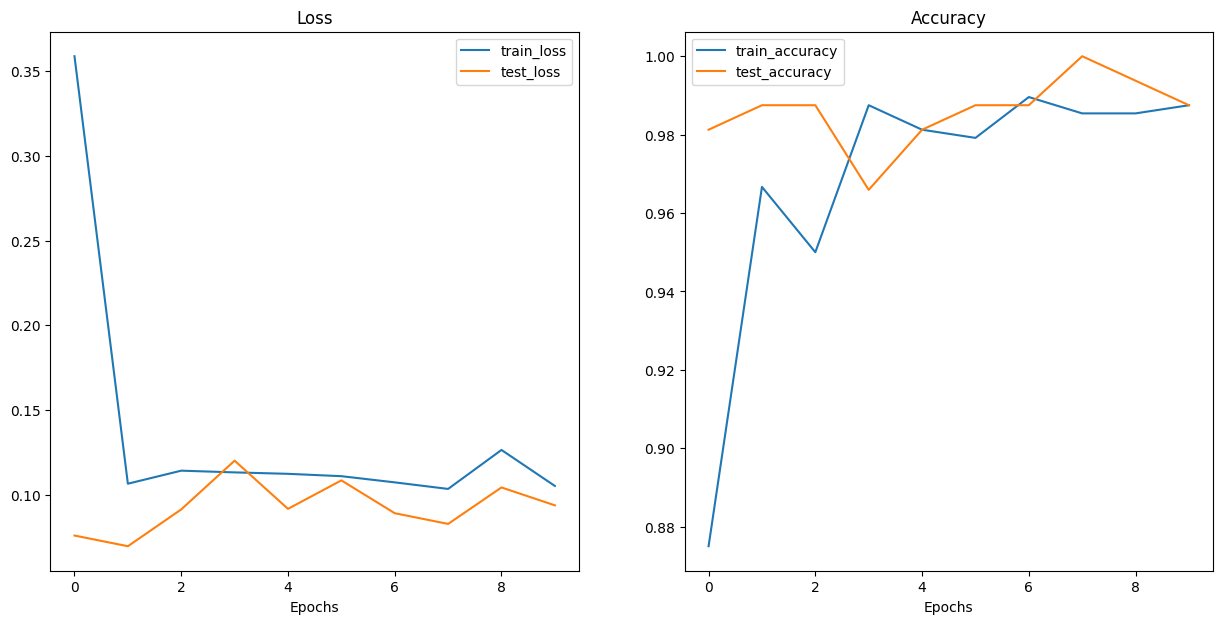

In [22]:
plot_loss_curves(results)

## 4. Try repeating the steps from excercise 3 but this time use the "`ViT_B_16_Weights.IMAGENET1K_SWAG_E2E_V1`" pretrained weights from [`torchvision.models.vit_b_16()`](https://pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html#torchvision.models.vit_b_16).
* Note: ViT pretrained with SWAG weights has a minimum input image size of (384, 384), though this is accessible in the weights `.transforms()` method.

In [23]:
vit_weights_swag = torchvision.models.ViT_B_16_Weights.IMAGENET1K_SWAG_E2E_V1
vit_swag = torchvision.models.vit_b_16(weights=vit_weights_swag).to(device)
transforms_swag = vit_weights_swag.transforms()

Downloading: "https://download.pytorch.org/models/vit_b_16_swag-9ac1b537.pth" to C:\Users\81456/.cache\torch\hub\checkpoints\vit_b_16_swag-9ac1b537.pth


100%|██████████| 331M/331M [00:08<00:00, 40.5MB/s] 


In [30]:
transforms_swag

ImageClassification(
    crop_size=[384]
    resize_size=[384]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [24]:
for param in vit_swag.parameters():
    param.requires_grad = False

In [27]:
from going_modular import data_setup

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir= train_dir, 
                                                                               test_dir= test_dir,
                                                                               train_transform= transforms_swag, 
                                                                               test_transform= transforms_swag, 
                                                                               batch_size= BATCH_SIZE)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x1d7d0a813a0>,
 ['pizza', 'steak', 'sushi'])

In [28]:
vit_swag.heads = nn.Sequential(
    nn.Linear(in_features=768, out_features=len(class_names), bias=True)
)

In [31]:
show_model_summary(vit_swag, input_size=(1, 3, 384, 384))

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 384, 384]     [1, 3]               768                  Partial
├─Conv2d (conv_proj)                                         [1, 3, 384, 384]     [1, 768, 24, 24]     (590,592)            False
├─Encoder (encoder)                                          [1, 577, 768]        [1, 577, 768]        443,136              False
│    └─Dropout (dropout)                                     [1, 577, 768]        [1, 577, 768]        --                   --
│    └─Sequential (layers)                                   [1, 577, 768]        [1, 577, 768]        --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 577, 768]        [1, 577, 768]        (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 577, 768]        [1, 5

In [32]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=vit_swag.parameters(), lr=3e-3, weight_decay=0.3)

epochs = 10

results = engine.train(model=vit_swag, train_dataloader=train_dataloader, test_dataloader=test_dataloader, optimizer=optimizer, loss_fn=loss_fn, device=device, epochs=epochs)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.1690 | train_acc: 0.9354 | test_loss: 0.0020 | test_acc: 1.0000
Epoch: 2 | train_loss: 0.0213 | train_acc: 0.9958 | test_loss: 0.0018 | test_acc: 1.0000
Epoch: 3 | train_loss: 0.0132 | train_acc: 0.9958 | test_loss: 0.0041 | test_acc: 1.0000
Epoch: 4 | train_loss: 0.0131 | train_acc: 1.0000 | test_loss: 0.0107 | test_acc: 1.0000
Epoch: 5 | train_loss: 0.0215 | train_acc: 0.9979 | test_loss: 0.0149 | test_acc: 1.0000
Epoch: 6 | train_loss: 0.0212 | train_acc: 1.0000 | test_loss: 0.0128 | test_acc: 1.0000
Epoch: 7 | train_loss: 0.0185 | train_acc: 1.0000 | test_loss: 0.0126 | test_acc: 1.0000
Epoch: 8 | train_loss: 0.0220 | train_acc: 0.9979 | test_loss: 0.0129 | test_acc: 1.0000
Epoch: 9 | train_loss: 0.0212 | train_acc: 1.0000 | test_loss: 0.0129 | test_acc: 1.0000
Epoch: 10 | train_loss: 0.0199 | train_acc: 0.9979 | test_loss: 0.0120 | test_acc: 1.0000


d:\PythonProjects\learn-ml\.venv\Lib\site-packages\torch\__init__.py:2271: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if not condition:


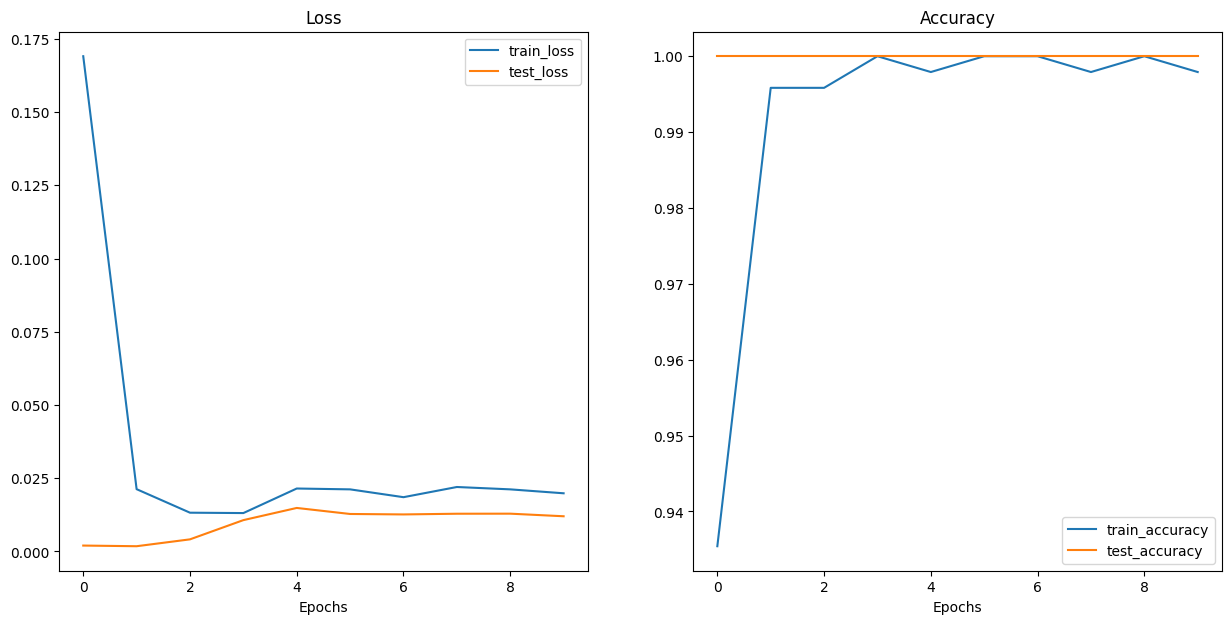

In [33]:
plot_loss_curves(results)

# 5. Our custom ViT model architecture closely mimics that of the ViT paper, however, our training recipe misses a few things. 
* Research some of the following topics from Table 3 in the ViT paper that we miss and write a sentence about each and how it might help with training:
    * **ImageNet-21k pretraining** 
    * **Learning rate warmup** 
    * **Learning rate decay** 
    * **Gradient clipping** 

All of the above are ways to prevent overfitting (regularization) and in the case of ImageNet-22k pretraining, it also helps to prevent underfitting (apply learned patterns from another dataset to your own for better performance). 

**ImageNet-21k pretraining** — The ViT paper first pretrains on ImageNet-21k (a much larger dataset with ~14M images and 21,841 classes) before fine-tuning on the target dataset, which helps the model learn rich, general-purpose visual representations that transfer well to downstream tasks and significantly reduces overfitting when the target dataset is small, since ViT lacks the inductive biases (e.g., translation equivariance) that CNNs inherently have.

**Learning rate warmup** — The paper uses a linear learning rate warmup over the first 10,000 steps, gradually increasing the learning rate from 0 to the peak value. This stabilizes early training because at initialization the model weights are random and large gradient updates can cause the transformer to converge to poor local minima; warmup gives the optimizer time to "explore" the loss landscape gently before making large updates.

**Learning rate decay** — After reaching the peak learning rate, the paper applies a cosine decay schedule that smoothly reduces the learning rate to near zero over the remaining training steps. This helps the model settle into a deeper minimum at the end of training—large steps early for fast progress, small steps later for fine-tuning the convergence—and is more effective than a constant learning rate or abrupt step decay.

**Gradient clipping** — The paper clips the global norm of gradients to a maximum value of 1.0 (i.e., if ‖g‖ > 1, scale g ← g / ‖g‖). This prevents the "exploding gradient" problem where a few abnormally large gradients (common in transformer training) dominate parameter updates and cause training instability; clipping ensures all updates stay bounded and training remains smooth.